# B1 vs B2 — Clean Official Evaluation & Error Analysis

**ConvNeXt-Tiny · DPD-Small · reproducible reporting notebook**

**Run All workflow:** setup → dataset audit → class imbalance → load locked predictions → official accuracy → four-way unseen errors → seen-pair bias → seen imbalance/accuracy association → confusion matrices → final summary.

**Default mode: `saved_predictions`**. This regenerates every analysis figure and table from the **original B1 official test CSVs** and the **already evaluated B2 CSVs**. It **does not retrain or re-run model inference**, and does not select new checkpoints. This is intentional: it keeps the B1 error analysis consistent with the original reported results. To independently re-run inference, use the original inference notebook and then specify its final saved outputs here; do not treat such an inference run as model selection.

**Integrity:** all analyses use original 8,000 training images as metadata, official 2,000 seen and 1,448 unseen for final post-hoc evaluation; full 9,625 Cartesian candidates are assumed when deriving pair Top-1 from independent crop/disease Top-1. Top-5 is reported only from previously saved full-ranking metrics/predictions, never reconstructed from Top-1.

## 0 · Setup and configuration
Run from the top. Edit only this settings cell if your Google Drive folders are different.

In [ ]:
from google.colab import drive
from pathlib import Path
if not Path('/content/drive/MyDrive').is_dir():
    drive.mount('/content/drive')
else:
    print('Google Drive already mounted')

import json, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

BASE = Path('/content/drive/MyDrive')
DATA_ROOT = BASE / 'DPD-Small'
B1_ROOT = BASE / 'AML_B1_ConvNeXtTiny_V1_ResNet50_HigherWD' / 'stage3_official_evaluation'
EVAL_ROOT = BASE / 'AML_Unified_Evaluation' / 'B1_B2_ConvNeXt_evaluation_v1'

# Output is isolated. Original files and checkpoints are NEVER overwritten.
OUTPUT_ROOT = BASE / 'AML_Unified_Evaluation' / 'B1_B2_Organized_Posthoc_Analysis'
for folder in ['00_dataset','01_metrics','02_seen_errors','03_unseen_errors',
               '04_imbalance_vs_accuracy','05_confusion','06_presentation']:
    (OUTPUT_ROOT/folder).mkdir(parents=True, exist_ok=True)

MIN_CROP_IMAGES = 30
MIN_PAIR_TEST_SUPPORT = 5
PRESENTATION_CROP_IDS = [21, 51]   # Corn and Tomato; can change without changing metrics
sns.set_theme(style='whitegrid', context='notebook')
print('Output folder:', OUTPUT_ROOT)

Mounted at /content/drive
Output folder: /content/drive/MyDrive/AML_Unified_Evaluation/B1_B2_Organized_Posthoc_Analysis


## 1 · Load original dataset metadata and validate splits
The lecturer CSVs may be headerless. This section never uses official test labels to define candidate restrictions.

In [ ]:
COLS = ['filename','crop_id','disease_id','composition_id','crop_name','disease_name','composition_name']
def read_dpd(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f'Missing DPD CSV: {path}')
    with path.open(encoding='utf-8-sig') as f:
        header = f.readline().split(',')[0].strip().lower() == 'filename'
    df = pd.read_csv(path, header=0 if header else None, names=COLS, encoding='utf-8-sig')
    for c in ['crop_id','disease_id','composition_id']:
        df[c] = pd.to_numeric(df[c], errors='raise').astype(int)
    if not df.filename.is_unique:
        raise ValueError(f'Duplicate filename in {path}')
    return df

train_df = read_dpd(DATA_ROOT/'DPD_Small_train.csv')
seen_df = read_dpd(DATA_ROOT/'DPD_Small_test_seen.csv')
unseen_df = read_dpd(DATA_ROOT/'DPD_Small_test_unseen.csv')
assert (len(train_df),len(seen_df),len(unseen_df)) == (8000,2000,1448)
assert set(train_df.filename).isdisjoint(seen_df.filename)
assert set(train_df.filename).isdisjoint(unseen_df.filename)
assert set(seen_df.filename).isdisjoint(unseen_df.filename)
assert (train_df.crop_id.nunique(),train_df.disease_id.nunique()) == (55,175)

crop_names = train_df.drop_duplicates('crop_id').set_index('crop_id').crop_name.to_dict()
disease_names = train_df.drop_duplicates('disease_id').set_index('disease_id').disease_name.to_dict()
for table in [seen_df,unseen_df]:
    crop_names.update(table.drop_duplicates('crop_id').set_index('crop_id').crop_name.to_dict())
    disease_names.update(table.drop_duplicates('disease_id').set_index('disease_id').disease_name.to_dict())

TRAIN_PAIRS = set(zip(train_df.crop_id, train_df.disease_id))
print(f'Train: {len(train_df):,} | Official seen: {len(seen_df):,} | Official unseen: {len(unseen_df):,}')
print(f'Crops: {train_df.crop_id.nunique()} | Diseases: {train_df.disease_id.nunique()} | Training-seen pairs: {len(TRAIN_PAIRS)}')
print('Split integrity: PASS')

Train: 8,000 | Official seen: 2,000 | Official unseen: 1,448
Crops: 55 | Diseases: 175 | Training-seen pairs: 323
Split integrity: PASS


## 2 · Training dataset imbalance and host–disease dependency
Evidence about class frequency and host associations. These distributions are **training-only** and do not involve predictions.

In [ ]:
crop_counts = (train_df.groupby(['crop_id','crop_name']).size().reset_index(name='images')
               .sort_values('images',ascending=False))
disease_counts = (train_df.groupby(['disease_id','disease_name']).size().reset_index(name='images')
                  .sort_values('images',ascending=False))
pair_counts = (train_df.groupby(['crop_id','crop_name','disease_id','disease_name'])
               .size().reset_index(name='images').sort_values('images',ascending=False))
pair_counts['composition'] = pair_counts.crop_name.astype(str)+' + '+pair_counts.disease_name.astype(str)
host_counts = (train_df.groupby(['disease_id','disease_name'])
               .agg(images=('filename','size'),number_of_crops=('crop_id','nunique')).reset_index())

def category_summary(label, data):
    s=data.images
    return {'category':label,'classes':len(s),'min_images':int(s.min()),
            'median_images':float(s.median()),'max_images':int(s.max()),
            'classes_le_5':int((s<=5).sum()),'classes_le_10':int((s<=10).sum()),
            'max_min_ratio':round(float(s.max()/s.min()),1)}

imbalance_summary = pd.DataFrame([category_summary('Crop',crop_counts),
                                  category_summary('Disease',disease_counts),
                                  category_summary('Crop–disease pair',pair_counts)])
print('TRAINING IMBALANCE SUMMARY')
display(imbalance_summary)
print(f'Diseases found in exactly one crop: {(host_counts.number_of_crops==1).sum()} / {len(host_counts)}'
      f' = {100*(host_counts.number_of_crops==1).mean():.1f}%')
print('Largest crops:');display(crop_counts.head(10))
print('Largest diseases:');display(disease_counts.head(10))
for name,frame in [('imbalance_summary',imbalance_summary),('crop_counts',crop_counts),
                   ('disease_counts',disease_counts),('pair_counts',pair_counts),('host_counts',host_counts)]:
    frame.to_csv(OUTPUT_ROOT/'00_dataset'/f'{name}.csv',index=False)

TRAINING IMBALANCE SUMMARY


,category,classes,min_images,median_images,max_images,classes_le_5,classes_le_10,max_min_ratio
0,Crop,55,3,49.0,1164,7,14,388.0
1,Disease,175,1,10.0,1594,61,88,1594.0
2,Crop–disease pair,323,1,7.0,544,139,187,544.0


Diseases found in exactly one crop: 133 / 175 = 76.0%
Largest crops:


,crop_id,crop_name,images
51,51,tomato,1164
13,13,cassava,1160
0,0,apple,1016
21,21,corn,910
33,33,paddy,576
44,44,soybean,376
18,18,citrus,227
40,40,potato,215
27,27,grape,167
47,47,sugarcane,162


Largest diseases:


,disease_id,disease_name,images
9,9,healthy,1594
51,51,mosaic,564
10,10,rust,297
4,4,brown_spot,261
14,14,powdery_mildew,226
95,95,streak_virus,218
61,61,greening,195
33,33,bacterial_spot,188
139,139,late_blight,182
165,165,septoria_leaf_spot,182


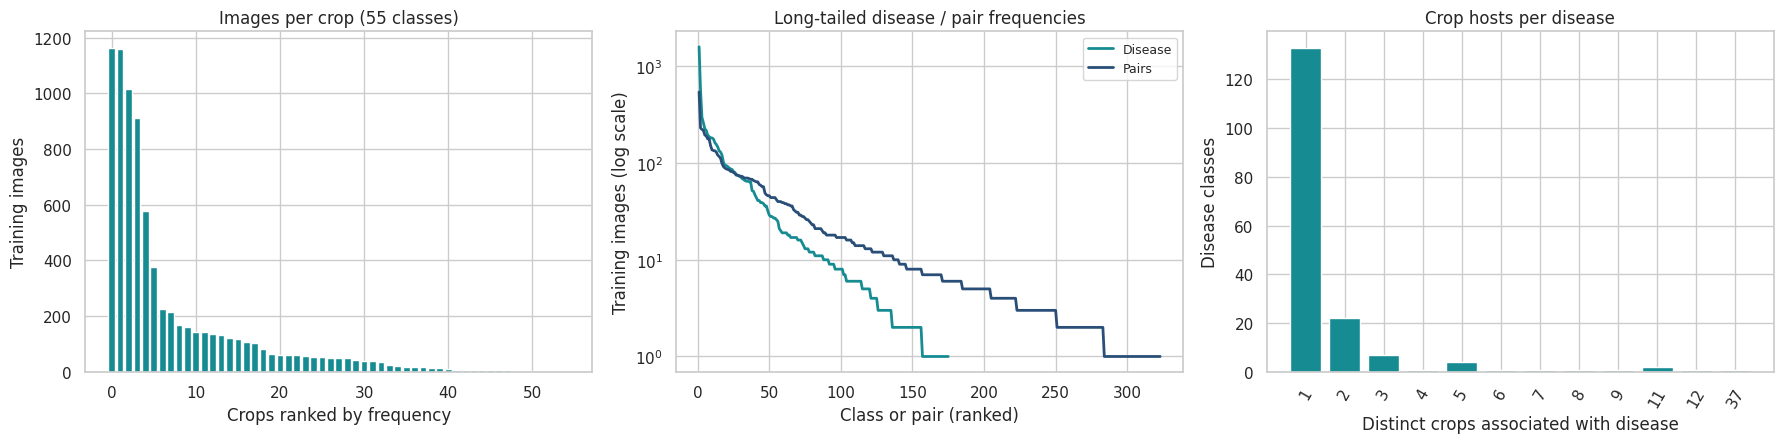

In [ ]:
fig, axes = plt.subplots(1,3,figsize=(18,4.6))
plot_crops=crop_counts.sort_values('images',ascending=False)
axes[0].bar(np.arange(len(plot_crops)),plot_crops.images,color='#168c92')
axes[0].set(title='Images per crop (55 classes)',xlabel='Crops ranked by frequency',ylabel='Training images')
axes[1].plot(np.arange(1,len(disease_counts)+1),disease_counts.images.to_numpy(),color='#168c92',linewidth=2,label='Disease')
axes[1].plot(np.arange(1,len(pair_counts)+1),pair_counts.images.to_numpy(),color='#294e77',linewidth=2,label='Pairs')
axes[1].set_yscale('log'); axes[1].set(title='Long-tailed disease / pair frequencies',xlabel='Class or pair (ranked)',ylabel='Training images (log scale)')
axes[1].legend(fontsize=9)
host_hist=host_counts.number_of_crops.value_counts().sort_index()
axes[2].bar(host_hist.index.astype(str),host_hist.values,color='#168c92')
axes[2].set(title='Crop hosts per disease',xlabel='Distinct crops associated with disease',ylabel='Disease classes')
axes[2].tick_params(axis='x',labelrotation=60)
fig.tight_layout();fig.savefig(OUTPUT_ROOT/'00_dataset'/'training_imbalance_overview.png',dpi=250,bbox_inches='tight');plt.show();plt.close(fig)

## 3 · Load the locked B1 and evaluated B2 predictions
**B1 source:** original Training Notebook Official CSVs. **B2 source:** independent Evaluation Notebook saved CSVs. If B2 CSV does not exist, stop and provide the correct existing file; do not silently substitute an unrelated model. Re-running this notebook does not redo GPU inference.

In [ ]:
B1_PRED_FILES = {split:B1_ROOT/f'official_{split}_predictions.csv' for split in ['seen','unseen']}
B2_PRED_FILES = {}
for split in ['seen','unseen']:
    hits=sorted(EVAL_ROOT.rglob(f'B2_{split}.csv')) if EVAL_ROOT.is_dir() else []
    if len(hits)!=1:
        raise FileNotFoundError(f'Expected exactly one B2_{split}.csv under {EVAL_ROOT}. Found: {hits}. Set EVAL_ROOT to the correct evaluation folder.')
    B2_PRED_FILES[split]=hits[0]

REQUIRED = ['filename','crop_id','disease_id','pred_crop_id','pred_disease_id']

def load_locked_prediction(path, truth, model, split):
    if not path.is_file(): raise FileNotFoundError(path)
    df=pd.read_csv(path)
    missing=set(REQUIRED)-set(df.columns)
    if missing: raise ValueError(f'{model} {split}: missing columns: {missing}')
    if not df.filename.is_unique or len(df)!=len(truth) or set(df.filename)!=set(truth.filename):
        raise ValueError(f'{model} {split}: official images do not match true split')
    df=df.set_index('filename').loc[truth.filename].reset_index()
    for c in REQUIRED[1:]:df[c]=pd.to_numeric(df[c],errors='raise').astype(int)
    assert np.array_equal(df.crop_id.to_numpy(),truth.crop_id.to_numpy())
    assert np.array_equal(df.disease_id.to_numpy(),truth.disease_id.to_numpy())
    df['crop_ok']=df.crop_id.eq(df.pred_crop_id)
    df['disease_ok']=df.disease_id.eq(df.pred_disease_id)
    # Valid only for UNRESTRICTED 55 x 175 Cartesian B1/B2 scoring.
    df['pair_ok']=df.crop_ok & df.disease_ok
    df['pred_pair_seen_in_train']=[(int(c),int(d)) in TRAIN_PAIRS for c,d in zip(df.pred_crop_id,df.pred_disease_id)]
    df['model']=model;df['split']=split
    return df

PRED={}
for model,paths in [('B1',B1_PRED_FILES),('B2',B2_PRED_FILES)]:
    PRED[model]={}
    for split,truth in [('seen',seen_df),('unseen',unseen_df)]:
        PRED[model][split]=load_locked_prediction(paths[split],truth,model,split)
        print(f'{model} {split}: {len(PRED[model][split])} matched images | {paths[split]}')
print('SAVED CSV REPRODUCIBILITY CHECK: PASS')

B1 seen: 2000 matched images | /content/drive/MyDrive/AML_B1_ConvNeXtTiny_V1_ResNet50_HigherWD/stage3_official_evaluation/official_seen_predictions.csv
B1 unseen: 1448 matched images | /content/drive/MyDrive/AML_B1_ConvNeXtTiny_V1_ResNet50_HigherWD/stage3_official_evaluation/official_unseen_predictions.csv
B2 seen: 2000 matched images | /content/drive/MyDrive/AML_Unified_Evaluation/B1_B2_ConvNeXt_evaluation_v1/predictions/B2_seen.csv
B2 unseen: 1448 matched images | /content/drive/MyDrive/AML_Unified_Evaluation/B1_B2_ConvNeXt_evaluation_v1/predictions/B2_unseen.csv
SAVED CSV REPRODUCIBILITY CHECK: PASS


## 4 · Official Top-1 metrics and original Top-5 evidence
Official seen/unseen composition accuracy is determined from matched original CSVs. Top-5 cannot be inferred from Top-1 columns: it is included only when the source evaluation has saved Top-5 results.

In [ ]:
def hm(a,b):return 0. if (a+b)==0 else 2*a*b/(a+b)
rows=[]
for model in ['B1','B2']:
    for task,col in [('Crop','crop_ok'),('Disease','disease_ok'),('Composition','pair_ok')]:
        s=PRED[model]['seen'][col].mean()*100
        u=PRED[model]['unseen'][col].mean()*100
        rows.append({'Model':model,'Task':task,'Seen Top-1 (%)':s,
                     'Unseen Top-1 (%)':u,'HM (%)':hm(s,u)})
top1=pd.DataFrame(rows)
display(top1.round(2))
top1.to_csv(OUTPUT_ROOT/'01_metrics'/'top1_recomputed_from_locked_csv.csv',index=False)

# If raw evaluation CSVs have recorded Top-5 success flags, report them too.
top5_rows=[]
for model in ['B1','B2']:
    for task,prefix in [('Crop','crop'),('Disease','disease'),('Composition','composition')]:
        key=f'{prefix}_top5_correct'
        if all(key in PRED[model][split].columns for split in ['seen','unseen']):
            s=PRED[model]['seen'][key].astype(bool).mean()*100
            u=PRED[model]['unseen'][key].astype(bool).mean()*100
            top5_rows.append({'Model':model,'Task':task,'Seen Top-5 (%)':s,
                              'Unseen Top-5 (%)':u,'HM (%)':hm(s,u)})
if top5_rows:
    top5=pd.DataFrame(top5_rows)
    display(top5.round(2))
    top5.to_csv(OUTPUT_ROOT/'01_metrics'/'top5_from_saved_predictions.csv',index=False)
else:
    print('Top-5 per-image flags not present in both saved CSVs. Refer to locked original metric reports; no Top-5 values invented.')

,Model,Task,Seen Top-1 (%),Unseen Top-1 (%),HM (%)
0,B1,Crop,89.30,73.07,80.37
1,B1,Disease,66.25,11.12,19.04
2,B1,Composition,63.65,6.56,11.90
3,B2,Crop,89.25,68.78,77.69
4,B2,Disease,66.45,10.08,17.51
5,B2,Composition,64.15,4.63,8.63


,Model,Task,Seen Top-5 (%),Unseen Top-5 (%),HM (%)
0,B1,Crop,96.20,84.74,90.11
1,B1,Disease,88.45,26.73,41.05
2,B1,Composition,84.00,18.85,30.80
3,B2,Crop,96.05,84.32,89.81
4,B2,Disease,88.90,27.97,42.55
5,B2,Composition,83.65,16.02,26.89


## 5 · Error breakdown for official seen and unseen
Use **both models on the same images** and separate the four mutually exclusive outcomes. Keep both seen and unseen results; do not use official errors to select checkpoints.

In [ ]:
TYPES=['Both correct','Crop correct, disease wrong','Crop wrong, disease correct','Both wrong']
def error_types(df):
    return np.select([df.crop_ok & df.disease_ok,df.crop_ok & ~df.disease_ok,
                      ~df.crop_ok & df.disease_ok,~df.crop_ok & ~df.disease_ok],
                     TYPES,default='Unknown')
error_rows=[]
for model in ['B1','B2']:
    for split in ['seen','unseen']:
        df=PRED[model][split]
        df['error_type']=error_types(df)
        counts=df.error_type.value_counts().reindex(TYPES,fill_value=0)
        for typ,n in counts.items():
            error_rows.append({'Model':model,'Split':split,'Error type':typ,
                               'Images':int(n),'Percentage (%)':n/len(df)*100})
errors=pd.DataFrame(error_rows)
for split in ['seen','unseen']:
    print(f'OFFICIAL {split.upper()} ERROR BREAKDOWN')
    display(errors[errors.Split==split].round(2))
errors.to_csv(OUTPUT_ROOT/'03_unseen_errors'/'all_four_way_error_breakdown.csv',index=False)

OFFICIAL SEEN ERROR BREAKDOWN


,Model,Split,Error type,Images,Percentage (%)
0,B1,seen,Both correct,1273,63.65
1,B1,seen,"Crop correct, disease wrong",513,25.65
2,B1,seen,"Crop wrong, disease correct",52,2.60
3,B1,seen,Both wrong,162,8.10
8,B2,seen,Both correct,1283,64.15
9,B2,seen,"Crop correct, disease wrong",502,25.10
10,B2,seen,"Crop wrong, disease correct",46,2.30
11,B2,seen,Both wrong,169,8.45


OFFICIAL UNSEEN ERROR BREAKDOWN


,Model,Split,Error type,Images,Percentage (%)
4,B1,unseen,Both correct,95,6.56
5,B1,unseen,"Crop correct, disease wrong",963,66.51
6,B1,unseen,"Crop wrong, disease correct",66,4.56
7,B1,unseen,Both wrong,324,22.38
12,B2,unseen,Both correct,67,4.63
13,B2,unseen,"Crop correct, disease wrong",929,64.16
14,B2,unseen,"Crop wrong, disease correct",79,5.46
15,B2,unseen,Both wrong,373,25.76


In [ ]:
# Seen-pair bias among crop-correct, disease-wrong errors (official unseen only)
bias_rows=[]
for model in ['B1','B2']:
    df=PRED[model]['unseen']
    subset=df[df.crop_ok & ~df.disease_ok]
    n=int(len(subset)); familiar=int(subset.pred_pair_seen_in_train.sum())
    bias_rows.append({'Model':model,'Unseen images':len(df),
        'Crop correct, disease wrong':n,'Such errors (%)':100*n/len(df),
        'Of these, predicted training-seen pair':familiar,
        'Seen-pair fraction among these errors (%)':100*familiar/n if n else np.nan,
        'Correct unseen pairs':int(df.pair_ok.sum())})
bias=pd.DataFrame(bias_rows)
print('CONDITIONAL TRAINING-SEEN PREDICTION ANALYSIS')
display(bias.round(2))
bias.to_csv(OUTPUT_ROOT/'03_unseen_errors'/'unseen_seen_pair_bias.csv',index=False)
print('Interpretation: association with known pairs is consistent with shortcut reliance, not proof of internal feature use.')

CONDITIONAL TRAINING-SEEN PREDICTION ANALYSIS


,Model,Unseen images,"Crop correct, disease wrong",Such errors (%),"Of these, predicted training-seen pair",Seen-pair fraction among these errors (%),Correct unseen pairs
0,B1,1448,963,66.51,704,73.10,95
1,B2,1448,929,64.16,721,77.61,67


Interpretation: association with known pairs is consistent with shortcut reliance, not proof of internal feature use.


## 6 · Paired same-image comparison: B1 vs B2
The most defensible direct contrast is the number of images only B1 gets right versus those only B2 gets right, on the same split.

In [ ]:
paired_results={}
for split in ['seen','unseen']:
    a=PRED['B1'][split][['filename','crop_id','disease_id','pair_ok']].rename(columns={'pair_ok':'B1_ok'})
    b=PRED['B2'][split][['filename','pair_ok']].rename(columns={'pair_ok':'B2_ok'})
    m=a.merge(b,on='filename',validate='one_to_one')
    m['outcome']=np.select([m.B1_ok & ~m.B2_ok,~m.B1_ok & m.B2_ok,
                            m.B1_ok & m.B2_ok,~m.B1_ok & ~m.B2_ok],
                           ['B1 only correct','B2 only correct','Both correct','Both wrong'],default='Unknown')
    paired_results[split]=m
    tab=m.outcome.value_counts().reindex(['B1 only correct','B2 only correct','Both correct','Both wrong'],fill_value=0)
    print('PAIRED COMPOSITION PREDICTIONS:',split.upper())
    display(tab.to_frame('Images'))
    tab.rename_axis('Outcome').reset_index(name='Images').to_csv(OUTPUT_ROOT/'03_unseen_errors'/f'paired_{split}_counts.csv',index=False)

PAIRED COMPOSITION PREDICTIONS: SEEN


,Images
outcome,
B1 only correct,75
B2 only correct,85
Both correct,1198
Both wrong,642


PAIRED COMPOSITION PREDICTIONS: UNSEEN


,Images
outcome,
B1 only correct,41
B2 only correct,13
Both correct,54
Both wrong,1340


## 7 · Official seen accuracy against training class frequency
This is a **post-hoc association** analysis, not proof of causation. Each pair is matched by the canonical `(crop_id, disease_id)`. We calculate image-weighted accuracy and per-composition rank correlation separately.

In [ ]:
train_support=(train_df.groupby(['crop_id','disease_id']).size()
               .reset_index(name='train_pair_images'))
seen_results=[]
for model in ['B1','B2']:
    df=PRED[model]['seen'].merge(train_support,on=['crop_id','disease_id'],how='left',validate='many_to_one')
    assert df.train_pair_images.notna().all()
    df['frequency_group']=pd.cut(df.train_pair_images,bins=[0,5,10,30,100,np.inf],
                                 labels=['1–5','6–10','11–30','31–100','101+'])
    df['model']=model
    seen_results.append(df)
all_seen=pd.concat(seen_results,ignore_index=True)
frequency=(all_seen.groupby(['model','frequency_group'],observed=False)
           .agg(test_images=('filename','size'),correct_pairs=('pair_ok','sum'),
                pair_accuracy=('pair_ok','mean'),crop_accuracy=('crop_ok','mean'),
                disease_accuracy=('disease_ok','mean')).reset_index())
for col in ['pair_accuracy','crop_accuracy','disease_accuracy']:
    frequency[col]=frequency[col]*100
print('OFFICIAL SEEN ACCURACY BY TRAINING PAIR SUPPORT (image-weighted)')
display(frequency.round(2))
frequency.to_csv(OUTPUT_ROOT/'04_imbalance_vs_accuracy'/'frequency_groups_seen.csv',index=False)

pair_seen=(all_seen.groupby(['model','crop_id','disease_id','train_pair_images'])
           .agg(test_images=('filename','size'),correct_pairs=('pair_ok','sum'),
                accuracy=('pair_ok','mean')).reset_index())
pair_seen['accuracy_pct']=pair_seen.accuracy*100
pair_seen['crop_name']=pair_seen.crop_id.map(crop_names)
pair_seen['disease_name']=pair_seen.disease_id.map(disease_names)
pair_seen['composition']=pair_seen.crop_name.astype(str)+' + '+pair_seen.disease_name.astype(str)
pair_seen.to_csv(OUTPUT_ROOT/'04_imbalance_vs_accuracy'/'per_composition_seen_accuracy.csv',index=False)

corr=[]
for model,g in pair_seen.groupby('model'):
    corr.append({'Model':model,'Pairs represented in seen test':len(g),
                 'Spearman rho':g.train_pair_images.corr(g.accuracy_pct,method='spearman'),
                 'Macro pair accuracy (%)':g.accuracy_pct.mean()})
print('PAIR-LEVEL TRAIN SUPPORT CORRELATION (unweighted by test count)')
display(pd.DataFrame(corr).round(3))
pd.DataFrame(corr).to_csv(OUTPUT_ROOT/'04_imbalance_vs_accuracy'/'frequency_correlations.csv',index=False)
print('Note: some groups/pairs have very few test samples; inspect n before generalising.')

OFFICIAL SEEN ACCURACY BY TRAINING PAIR SUPPORT (image-weighted)


,model,frequency_group,test_images,correct_pairs,pair_accuracy,crop_accuracy,disease_accuracy
0,B1,1–5,207,32,15.46,51.21,23.19
1,B1,6–10,110,62,56.36,80.00,64.55
2,B1,11–30,282,176,62.41,89.01,65.96
3,B1,31–100,759,495,65.22,94.47,66.53
4,B1,101+,642,508,79.13,97.20,80.22
5,B2,1–5,207,29,14.01,48.79,21.26
6,B2,6–10,110,65,59.09,81.82,65.45
7,B2,11–30,282,183,64.89,89.36,67.38
8,B2,31–100,759,501,66.01,95.13,67.19
9,B2,101+,642,505,78.66,96.57,79.91


PAIR-LEVEL TRAIN SUPPORT CORRELATION (unweighted by test count)


,Model,Pairs represented in seen test,Spearman rho,Macro pair accuracy (%)
0,B1,323,0.531,42.913
1,B2,323,0.556,42.934


Note: some groups/pairs have very few test samples; inspect n before generalising.


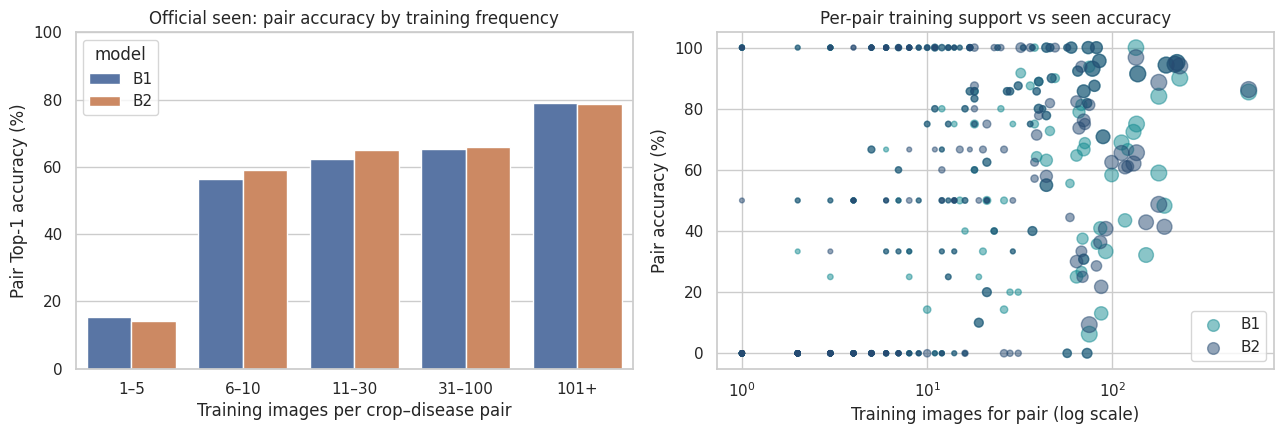

Low-support pairs (train ≤10, official seen test ≥5)


,model,crop_id,disease_id,train_pair_images,test_images,correct_pairs,accuracy,accuracy_pct,crop_name,disease_name,composition
301,B1,51,162,10,7,1,0.14,14.29,tomato,blight_leaf,tomato + blight_leaf
117,B1,21,76,7,5,3,0.60,60.00,corn,smut,corn + smut
30,B1,3,9,5,6,4,0.67,66.67,basil,healthy,basil + healthy
272,B1,48,9,7,5,5,1.00,100.00,sunflower,healthy,sunflower + healthy
624,B2,51,162,10,7,0,0.00,0.00,tomato,blight_leaf,tomato + blight_leaf
440,B2,21,76,7,5,3,0.60,60.00,corn,smut,corn + smut
353,B2,3,9,5,6,4,0.67,66.67,basil,healthy,basil + healthy
595,B2,48,9,7,5,5,1.00,100.00,sunflower,healthy,sunflower + healthy


In [ ]:
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
sns.barplot(data=frequency,x='frequency_group',y='pair_accuracy',hue='model',ax=axes[0])
axes[0].set(title='Official seen: pair accuracy by training frequency',xlabel='Training images per crop–disease pair',ylabel='Pair Top-1 accuracy (%)',ylim=(0,100))
for model,color in [('B1','#168c92'),('B2','#274b72')]:
    sub=pair_seen[pair_seen.model==model]
    axes[1].scatter(sub.train_pair_images,sub.accuracy_pct,
                    s=np.clip(sub.test_images*4,12,130),alpha=.5,label=model,color=color)
axes[1].set_xscale('log')
axes[1].set(title='Per-pair training support vs seen accuracy',xlabel='Training images for pair (log scale)',ylabel='Pair accuracy (%)',ylim=(-5,105))
axes[1].legend();fig.tight_layout()
fig.savefig(OUTPUT_ROOT/'04_imbalance_vs_accuracy'/'seen_accuracy_vs_training_frequency.png',dpi=300,bbox_inches='tight')
plt.show();plt.close(fig)

low=pair_seen[(pair_seen.train_pair_images<=10)&(pair_seen.test_images>=MIN_PAIR_TEST_SUPPORT)]
print(f'Low-support pairs (train ≤10, official seen test ≥{MIN_PAIR_TEST_SUPPORT})')
display(low.sort_values(['model','accuracy_pct','test_images'],ascending=[True,True,False]).head(25).round(2))
low.to_csv(OUTPUT_ROOT/'04_imbalance_vs_accuracy'/'low_support_seen_pairs.csv',index=False)

## 8 · B1 vs B2 seen accuracy by crop
This ranks all eligible crops but is a **descriptive, post-hoc** comparison. Do not cherry-pick one crop as proof of overall architecture superiority.

In [ ]:
crop_rows=[]
for crop_id in sorted(seen_df.crop_id.unique()):
    aa=PRED['B1']['seen'].query('crop_id == @crop_id')
    bb=PRED['B2']['seen'].query('crop_id == @crop_id')
    assert len(aa)==len(bb)
    a=aa.set_index('filename').pair_ok
    b=bb.set_index('filename').pair_ok.loc[a.index]
    crop_rows.append({'Crop ID':int(crop_id),'Crop':crop_names.get(int(crop_id),str(crop_id)),
                      'Images':len(a),'B1 Accuracy (%)':100*a.mean(),'B2 Accuracy (%)':100*b.mean(),
                      'Gap (pp)':100*(a.mean()-b.mean()),
                      'B1 only correct':int((a&~b).sum()),'B2 only correct':int((~a&b).sum())})
crop_comparison=pd.DataFrame(crop_rows)
ranked=crop_comparison[crop_comparison.Images>=MIN_CROP_IMAGES].copy()
ranked['Abs gap (pp)']=ranked['Gap (pp)'].abs()
ranked=ranked.sort_values('Abs gap (pp)',ascending=False)
print('Crops ranked by absolute B1-B2 seen pair accuracy gap (minimum 30 seen images):')
display(ranked.head(15).round(2))
crop_comparison.to_csv(OUTPUT_ROOT/'02_seen_errors'/'all_crop_accuracy_comparison.csv',index=False)

Crops ranked by absolute B1-B2 seen pair accuracy gap (minimum 30 seen images):


,Crop ID,Crop,Images,B1 Accuracy (%),B2 Accuracy (%),Gap (pp),B1 only correct,B2 only correct,Abs gap (pp)
47,47,sugarcane,44,47.73,56.82,-9.09,0,4,9.09
40,40,potato,53,67.92,73.58,-5.66,0,3,5.66
27,27,grape,41,73.17,78.05,-4.88,0,2,4.88
18,18,citrus,43,86.05,90.70,-4.65,1,3,4.65
33,33,paddy,158,41.77,45.57,-3.80,4,10,3.80
36,36,peach,40,70.00,72.50,-2.50,1,2,2.50
21,21,corn,206,78.16,75.73,2.43,7,2,2.43
53,53,wheat,42,45.24,42.86,2.38,2,1,2.38
30,30,mango,53,58.49,60.38,-1.89,1,2,1.89
51,51,tomato,291,62.89,61.17,1.72,21,16,1.72


## 9 · Presentation-ready per-crop disease confusion matrices (Official Seen)
Both models use identical true rows, predicted columns, and fixed 0–100% scale. A wrong crop is placed in **Other crop**. Every row is normalised by its number of test images. Includes all within-crop predicted disease classes, not just the true ones.

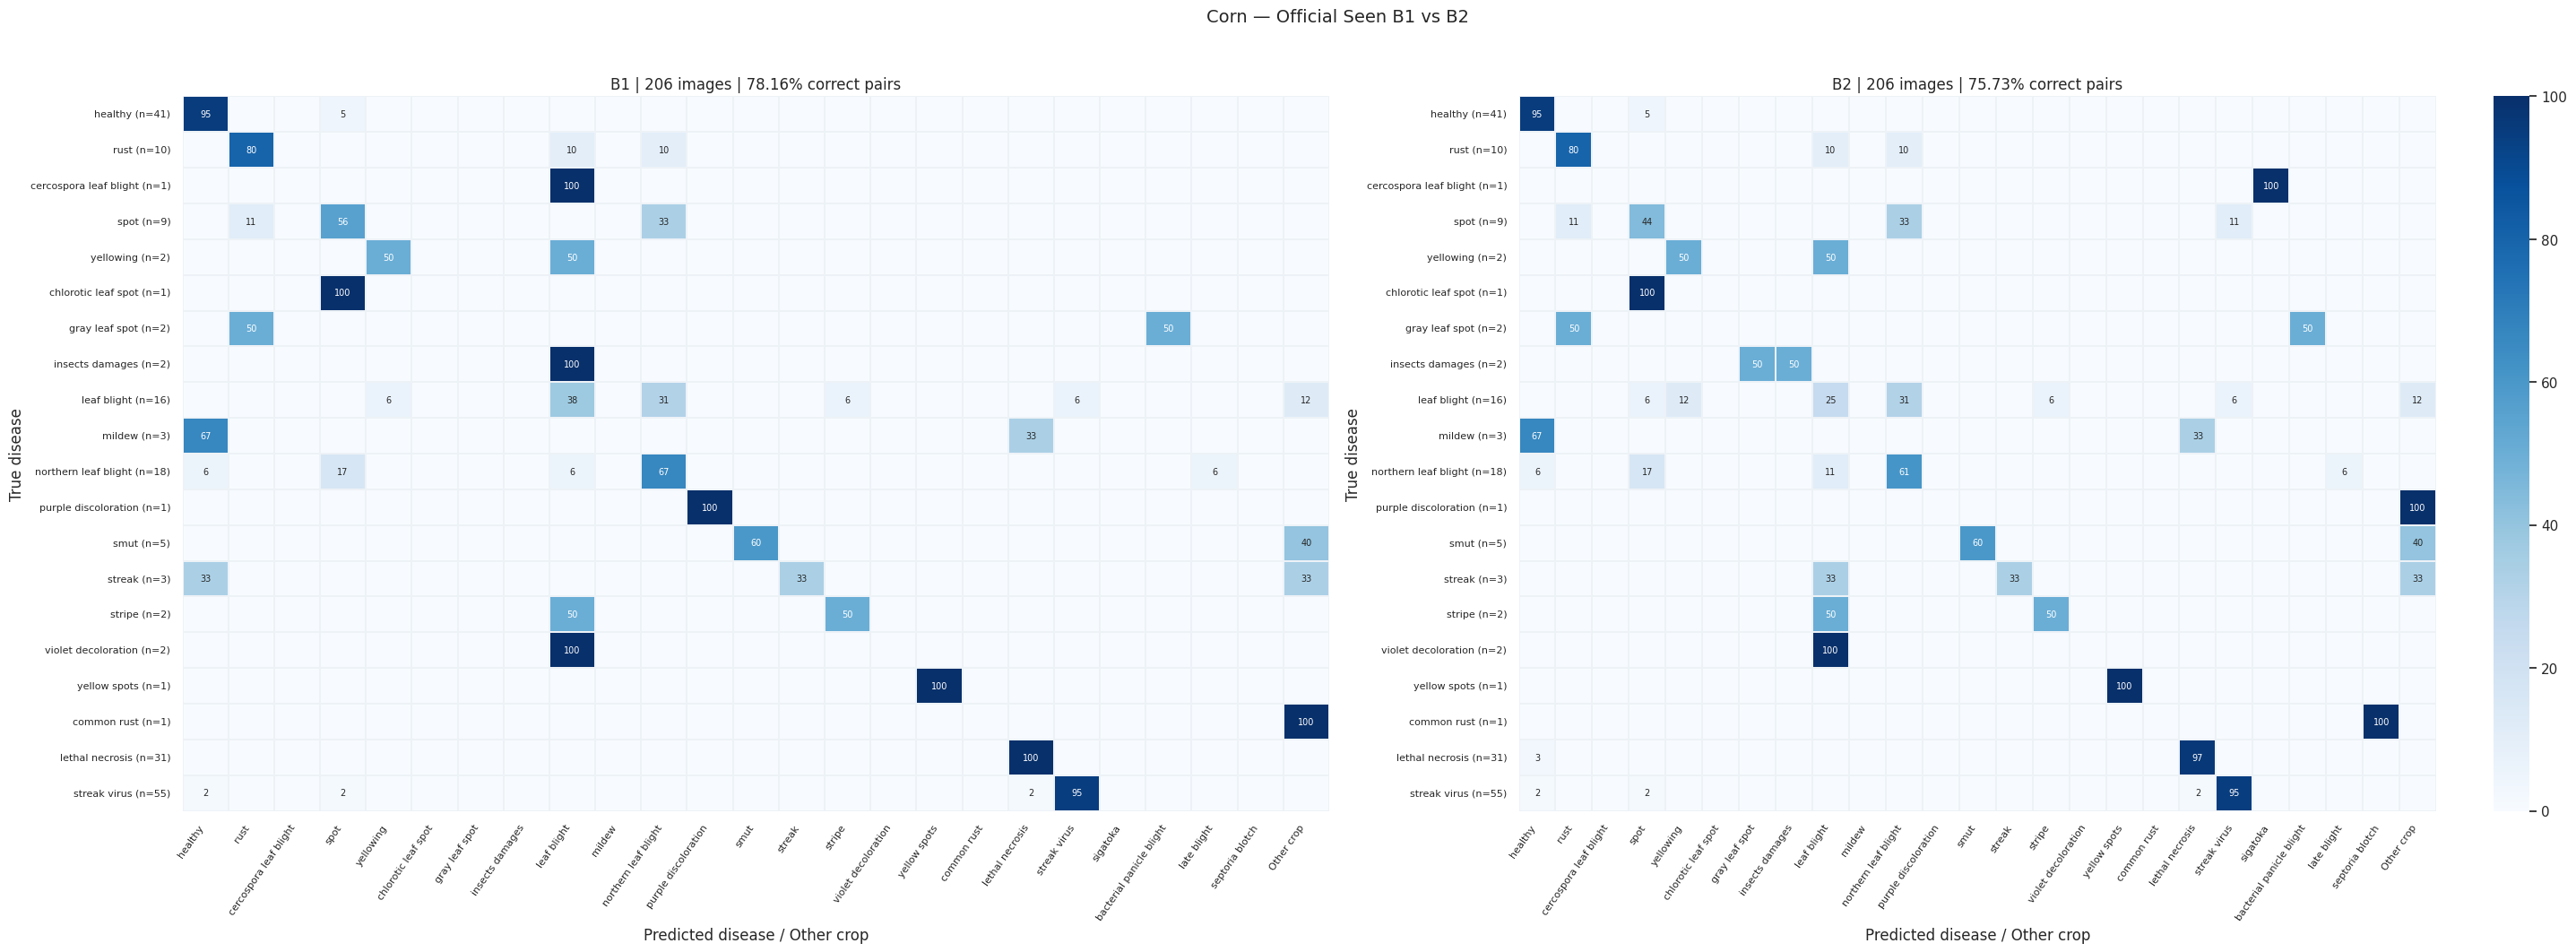

Saved: /content/drive/MyDrive/AML_Unified_Evaluation/B1_B2_Organized_Posthoc_Analysis/06_presentation/B1_vs_B2_seen_crop_21.png


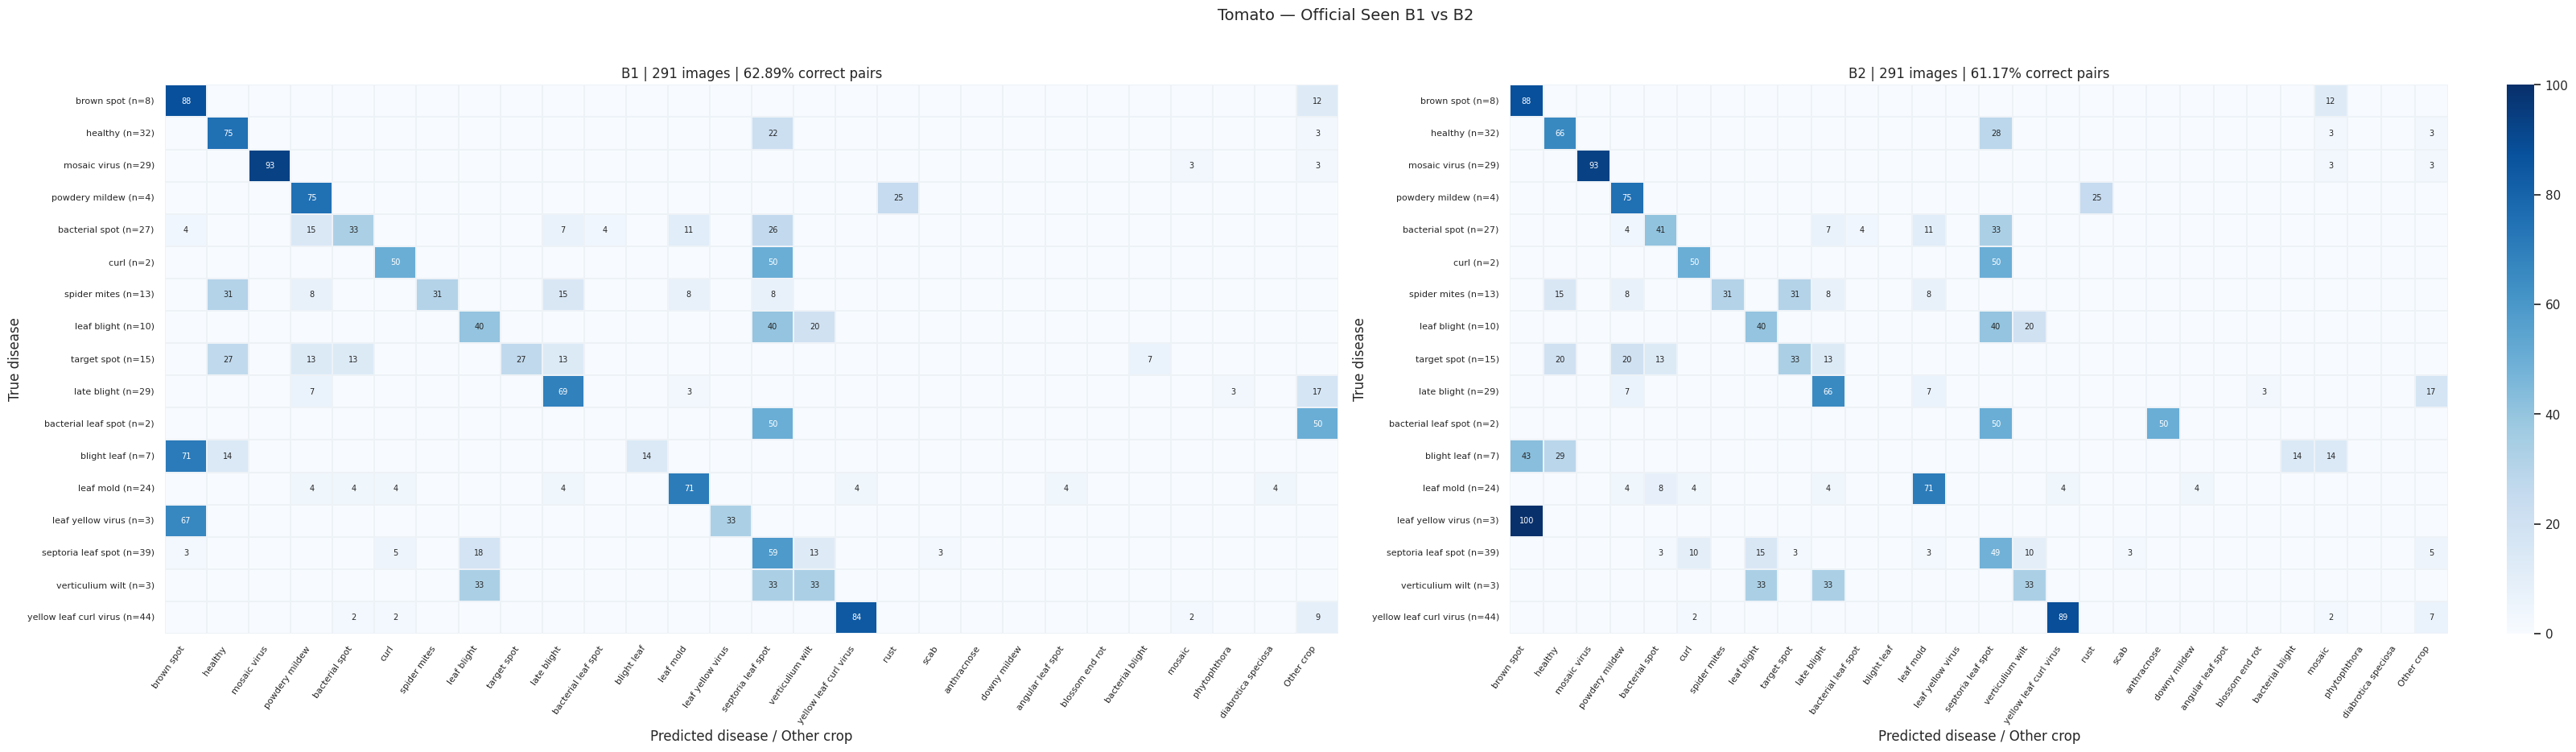

Saved: /content/drive/MyDrive/AML_Unified_Evaluation/B1_B2_Organized_Posthoc_Analysis/06_presentation/B1_vs_B2_seen_crop_51.png


In [ ]:
def pretty_disease(did):
    return str(disease_names.get(int(did),f'Disease {did}')).replace('_',' ')

def confusion_for_crop(crop_id, split='seen'):
    sub={m:PRED[m][split].query('crop_id == @crop_id').copy() for m in ['B1','B2']}
    truth=sub['B1']; assert len(truth)==len(sub['B2'])
    if truth.empty:
        print(f'No {split} images for crop {crop_id}');return
    true_ids=sorted(truth.disease_id.unique())
    extras=set()
    for df in sub.values():
        extras.update(df.loc[df.pred_crop_id==crop_id,'pred_disease_id'].unique())
    pred_ids=true_ids+sorted(set(map(int,extras))-set(true_ids))
    columns=[str(x) for x in pred_ids]+['Other crop']
    rows=[str(x) for x in true_ids]
    row_n=truth.disease_id.value_counts()
    ylabels=[f'{pretty_disease(d)} (n={row_n[d]})' for d in true_ids]
    xlabels=[pretty_disease(d) for d in pred_ids]+['Other crop']
    fig,axs=plt.subplots(1,2,figsize=(max(16,len(columns)*1.2),max(6,len(rows)*0.42+2)))
    for ax,model in zip(axs,['B1','B2']):
        df=sub[model]
        labels=np.where(df.pred_crop_id.eq(crop_id),df.pred_disease_id.astype(str),'Other crop')
        counts=pd.crosstab(df.disease_id.astype(str),pd.Series(labels,index=df.index))
        counts=counts.reindex(index=rows,columns=columns,fill_value=0)
        pct=counts.div(counts.sum(axis=1),axis=0).mul(100).fillna(0)
        annot=pct.map(lambda x: f'{x:.0f}' if x>=0.5 else (f'{x:.1f}' if x>0 else ''))
        sns.heatmap(pct,cmap='Blues',vmin=0,vmax=100,annot=annot,fmt='',
                    linewidths=.2,linecolor='#edf2f7',cbar=(model=='B2'),
                    annot_kws={'fontsize':7},ax=ax)
        ax.set_title(f'{model} | {len(df)} images | {100*df.pair_ok.mean():.2f}% correct pairs')
        ax.set_xticklabels(xlabels,rotation=55,ha='right',fontsize=8)
        ax.set_yticklabels(ylabels,rotation=0,fontsize=8)
        ax.set_xlabel('Predicted disease / Other crop');ax.set_ylabel('True disease')
        ax.tick_params(axis='y',labelleft=True)
        pct.to_csv(OUTPUT_ROOT/'05_confusion'/f'{model}_{split}_crop_{crop_id}_percent.csv')
    fig.suptitle(f'{str(crop_names.get(crop_id,crop_id)).title()} — Official {split.title()} B1 vs B2',fontsize=14,y=1.02)
    fig.tight_layout()
    path=OUTPUT_ROOT/'06_presentation'/f'B1_vs_B2_{split}_crop_{crop_id}.png'
    fig.savefig(path,dpi=260,bbox_inches='tight',facecolor='white')
    plt.show();plt.close(fig)
    print('Saved:',path)

for crop_id in PRESENTATION_CROP_IDS:
    confusion_for_crop(crop_id,'seen')

## 10 · Official seen composition confusion and most difficult pairs

Export full composition-level count matrices, plus Top-15 best/worst **with a minimum of 5 official seen examples**. The per-crop matrices in Section 9 remain the more readable figures for presentation. Rankings are for post-hoc explanation only.

In [ ]:
for model in ['B1','B2']:
    df=PRED[model]['seen'].copy()
    df['true_pair']=[f'{c}|{d}' for c,d in zip(df.crop_id,df.disease_id)]
    df['pred_pair']=[f'{c}|{d}' for c,d in zip(df.pred_crop_id,df.pred_disease_id)]
    counts=pd.crosstab(df.true_pair,df.pred_pair)
    counts.to_csv(OUTPUT_ROOT/'05_confusion'/f'{model}_full_seen_composition_counts.csv')
    subset=pair_seen[(pair_seen.model==model)&(pair_seen.test_images>=MIN_PAIR_TEST_SUPPORT)]
    cols=['composition','train_pair_images','test_images','correct_pairs','accuracy_pct']
    best=subset.sort_values(['accuracy_pct','test_images'],ascending=[False,False]).head(15)[cols]
    worst=subset.sort_values(['accuracy_pct','test_images'],ascending=[True,False]).head(15)[cols]
    best.to_csv(OUTPUT_ROOT/'05_confusion'/f'{model}_top15_best_pairs.csv',index=False)
    worst.to_csv(OUTPUT_ROOT/'05_confusion'/f'{model}_top15_worst_pairs.csv',index=False)
    print(f'{model}: composition confusion count matrix {counts.shape}')
    print('Worst supported compositions:')
    display(worst.round(2))

B1: composition confusion count matrix (323, 375)
Worst supported compositions:


,composition,train_pair_images,test_images,correct_pairs,accuracy_pct
196,paddy + hispa,73,12,0,0.00
15,apple + scab,57,9,0,0.00
186,paddy + healthy,75,32,2,6.25
318,wheat + stripe_rust,19,10,1,10.00
254,soybean + caterpillar,87,23,3,13.04
188,paddy + bacterial_blight,26,7,1,14.29
301,tomato + blight_leaf,10,7,1,14.29
3,apple + black_rot,21,10,2,20.00
68,cassava + brown_leaf_spot,28,5,1,20.00
219,peanut + healthy,31,5,1,20.00


B2: composition confusion count matrix (323, 349)
Worst supported compositions:


,composition,train_pair_images,test_images,correct_pairs,accuracy_pct
519,paddy + hispa,73,12,0,0.00
338,apple + scab,57,9,0,0.00
511,paddy + bacterial_blight,26,7,0,0.00
624,tomato + blight_leaf,10,7,0,0.00
391,cassava + brown_leaf_spot,28,5,0,0.00
542,peanut + healthy,31,5,0,0.00
638,wheat + loose_smut,16,5,0,0.00
509,paddy + healthy,75,32,3,9.38
641,wheat + stripe_rust,19,10,1,10.00
326,apple + black_rot,21,10,2,20.00


## 11 · Representative misclassified-image galleries (post-hoc only)

Show correct crop / wrong disease cases and B1-only correct / B2 wrong cases using the already indexed image files. Image galleries are qualitative **examples**, not proof of the cause of the error. They can be safely regenerated with `Run All`.

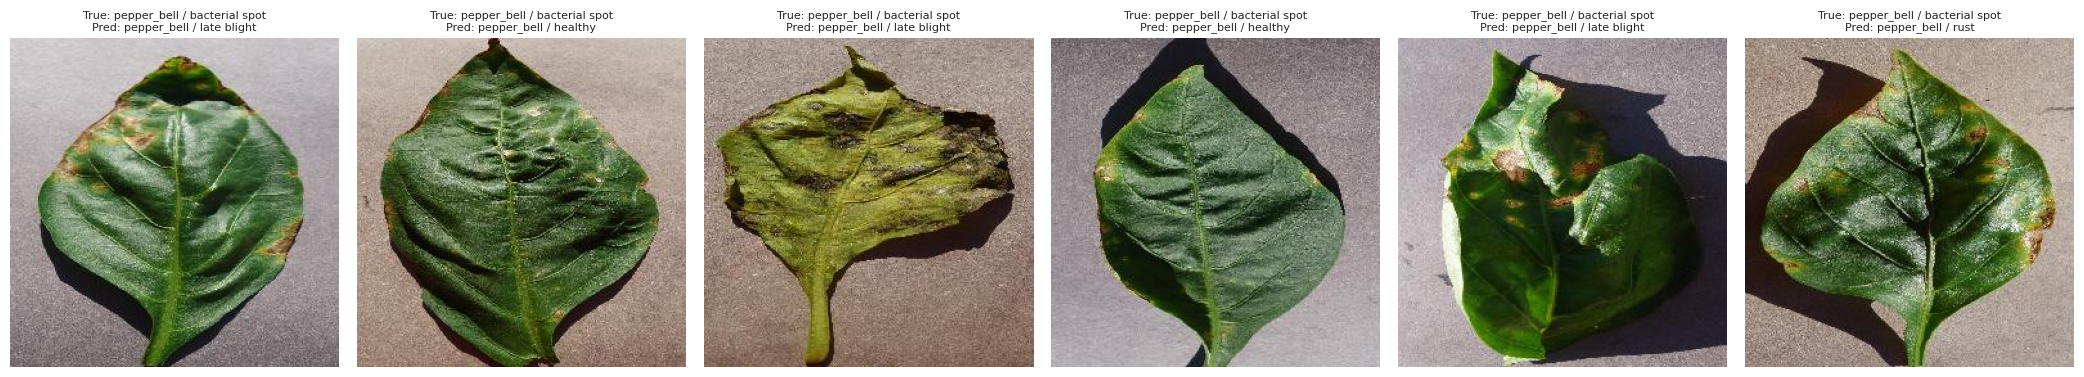

Saved: /content/drive/MyDrive/AML_Unified_Evaluation/B1_B2_Organized_Posthoc_Analysis/06_presentation/B1_unseen_crop_correct_disease_wrong.png


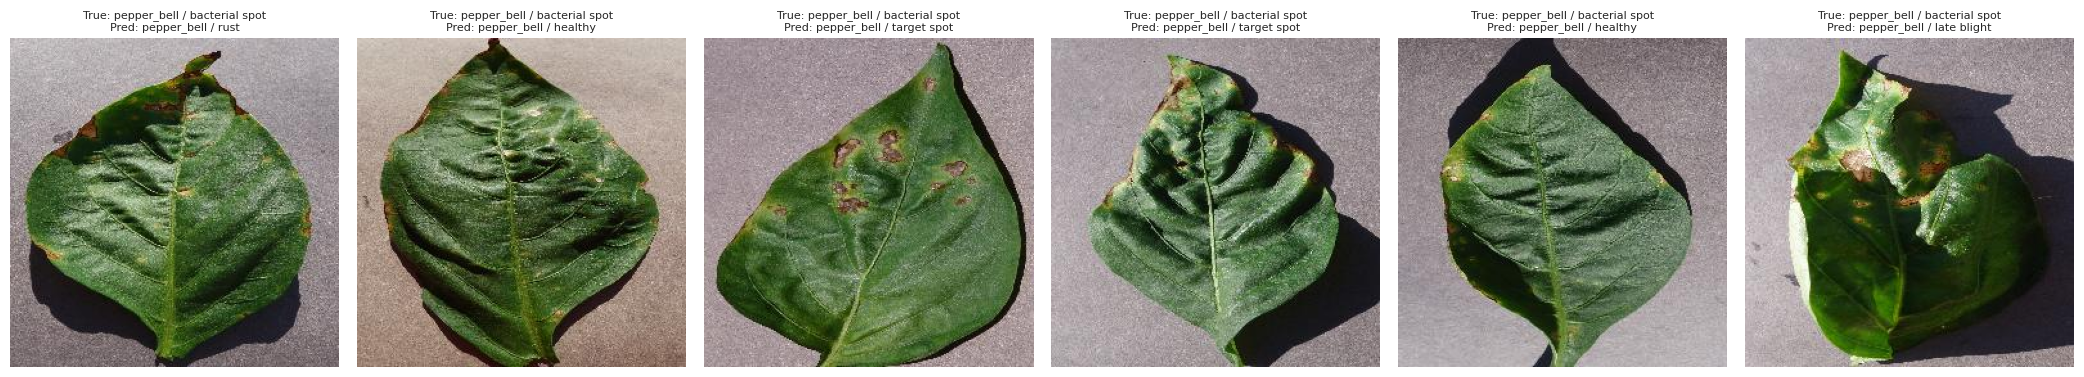

Saved: /content/drive/MyDrive/AML_Unified_Evaluation/B1_B2_Organized_Posthoc_Analysis/06_presentation/B2_unseen_crop_correct_disease_wrong.png


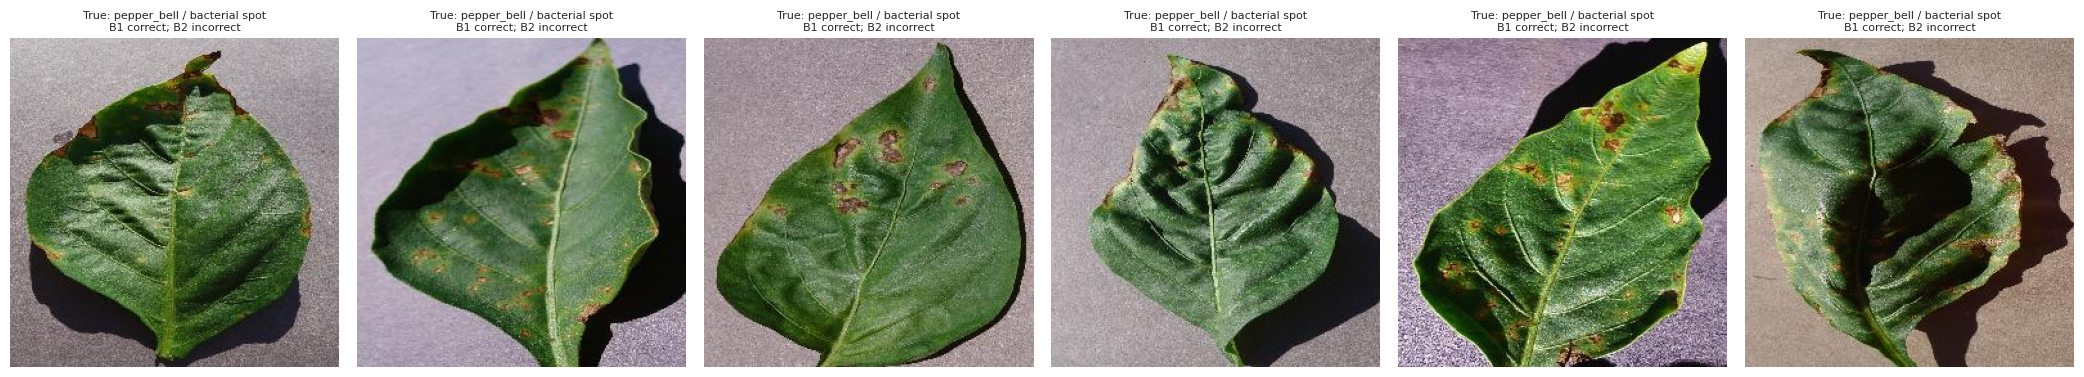

Saved: /content/drive/MyDrive/AML_Unified_Evaluation/B1_B2_Organized_Posthoc_Analysis/06_presentation/B1_only_correct_unseen_examples.png


In [ ]:
from PIL import Image
IMAGE_DIR=DATA_ROOT/'images'
# Filename resolution requires no extra inference and does not copy images.
image_index={}
if IMAGE_DIR.is_dir():
    for f in IMAGE_DIR.rglob('*'):
        if f.is_file() and f.suffix.lower() in {'.jpg','.jpeg','.png','.webp'}:
            image_index.setdefault(f.name,f)
else:
    print('Images folder absent, skipping galleries:',IMAGE_DIR)

def make_gallery(subset,filename,label,max_items=6):
    subset=subset.head(max_items)
    if subset.empty or not image_index:
        print('No gallery images available:',filename);return
    fig,axs=plt.subplots(1,len(subset),figsize=(3.5*len(subset),4.0))
    axs=np.atleast_1d(axs)
    for ax,(_,row) in zip(axs,subset.iterrows()):
        img=image_index.get(str(row.filename))
        if img is not None:
            with Image.open(img) as im:
                ax.imshow(im.convert('RGB'))
        ax.set_axis_off()
        ax.set_title(label(row),fontsize=8)
    fig.tight_layout()
    path=OUTPUT_ROOT/'06_presentation'/filename
    fig.savefig(path,dpi=240,bbox_inches='tight',facecolor='white')
    plt.show();plt.close(fig)
    print('Saved:',path)

for model in ['B1','B2']:
    src=PRED[model]['unseen']
    sub=src[src.crop_ok & ~src.disease_ok]
    def label_fn(r):
        return (f'True: {crop_names.get(r.crop_id,r.crop_id)} / '
                f'{pretty_disease(r.disease_id)}\nPred: {crop_names.get(r.pred_crop_id,r.pred_crop_id)} / '
                f'{pretty_disease(r.pred_disease_id)}')
    make_gallery(sub, f'{model}_unseen_crop_correct_disease_wrong.png',label_fn)

b1_unseen=PRED['B1']['unseen'].set_index('filename')
chosen=paired_results['unseen'].query('outcome == "B1 only correct"').copy()
chosen=chosen.join(b1_unseen[['pred_crop_id','pred_disease_id']],on='filename')
make_gallery(chosen,'B1_only_correct_unseen_examples.png',
             lambda r:f'True: {crop_names.get(r.crop_id,r.crop_id)} / {pretty_disease(r.disease_id)}\nB1 correct; B2 incorrect')

## 12 · Final one-page evidence summary and provenance
All model-selection decisions must have been finalised before official testing. These post-hoc analyses are intended for reporting only.

In [ ]:
summary_lines=[
    'B1 and B2 official evaluation summary (locked CSV sources)',
    f'Train images: {len(train_df)}; official seen: {len(seen_df)}; official unseen: {len(unseen_df)}',
    f'Train-seen pairs: {len(TRAIN_PAIRS)}; disease classes observed with only one host crop: {int((host_counts.number_of_crops==1).sum())}/{len(host_counts)}',
]
for model in ['B1','B2']:
    r=top1[(top1.Model==model)&(top1.Task=='Composition')].iloc[0]
    br=bias[bias.Model==model].iloc[0]
    summary_lines.append(f'{model}: composition seen={r["Seen Top-1 (%)"]:.2f}%; unseen={r["Unseen Top-1 (%)"]:.2f}%; HM={r["HM (%)"]:.2f}%.')
    summary_lines.append(f'{model}: crop-correct/disease-wrong unseen={int(br["Crop correct, disease wrong"])}; of those familiar predicted pair={int(br["Of these, predicted training-seen pair"])} ({br["Seen-pair fraction among these errors (%)"]:.2f}%).')
summary_lines += [
    'Caution: training imbalance and seen-pair prediction association do not causally prove shortcut learning.',
    'Caution: official test outcomes were NOT used to tune model weights, checkpoint selection, score calibration, or permissible pair catalogue.',
    'Source B1: '+str(B1_PRED_FILES['seen']),
    'Source B2: '+str(B2_PRED_FILES['seen']),
]
print('\n'.join(summary_lines))
(OUTPUT_ROOT/'01_metrics'/'summary_and_provenance.txt').write_text('\n'.join(summary_lines),encoding='utf-8')
print('\nCOMPLETED. Output:',OUTPUT_ROOT)

B1 and B2 official evaluation summary (locked CSV sources)
Train images: 8000; official seen: 2000; official unseen: 1448
Train-seen pairs: 323; disease classes observed with only one host crop: 133/175
B1: composition seen=63.65%; unseen=6.56%; HM=11.90%.
B1: crop-correct/disease-wrong unseen=963; of those familiar predicted pair=704 (73.10%).
B2: composition seen=64.15%; unseen=4.63%; HM=8.63%.
B2: crop-correct/disease-wrong unseen=929; of those familiar predicted pair=721 (77.61%).
Caution: training imbalance and seen-pair prediction association do not causally prove shortcut learning.
Caution: official test outcomes were NOT used to tune model weights, checkpoint selection, score calibration, or permissible pair catalogue.
Source B1: /content/drive/MyDrive/AML_B1_ConvNeXtTiny_V1_ResNet50_HigherWD/stage3_official_evaluation/official_seen_predictions.csv
Source B2: /content/drive/MyDrive/AML_Unified_Evaluation/B1_B2_ConvNeXt_evaluation_v1/predictions/B2_seen.csv

COMPLETED. Output: /

## Deliverables index

| Section | Output folder | What to use in report / presentation |
|---|---|---|
| 2 | `00_dataset/` | Training imbalance, 76% single-crop disease dependency |
| 4 | `01_metrics/` | Official Top-1 Seen / Unseen / HM, recorded Top-5 if available |
| 5–6 | `03_unseen_errors/` | Four-way errors, training-seen-pair bias, paired B1/B2 outcomes |
| 7 | `04_imbalance_vs_accuracy/` | Actual evidence about whether training frequency associates with seen accuracy |
| 8 | `02_seen_errors/` | Per-crop B1/B2 ranking |
| 9 | `05_confusion/` and `06_presentation/` | Full per-crop matrices and Corn/Tomato side-by-side PNGs |

**Note:** this notebook reports on saved inference; it is not a second independent reproduction of model inference. It deliberately avoids mixing your original B1 error charts with slightly different B1 re-inference. To audit a newly rerun evaluator, compare its prediction CSVs separately and report any differences honestly.